# El modelo X-13 de BCR: cómo funciona y réplica

**Proyecto BCR · Lab 2 · Épica E4 (SCRUM-23)**

BCR estima la producción de biocombustibles con **X-13ARIMA-SEATS**, un
programa libre del Census de EE.UU. No es un modelo propio: es una
herramienta estándar que usan institutos de estadística de todo el mundo
(INDEC incluido). Acá lo replicamos para tener el **número exacto a superar**.

> **Config exacta de BCR.** BCR nos pasó cuatro `.spc` (en `spc/`): biodiesel
> y bioetanol, cada uno **en log y en nivel**. `scripts/replica_x13.py` los usa
> tal cual (solo cambia la ruta al `.prn` por los datos). Ajustan el modelo
> desde 2013 (salvo bioetanol en log, desde 2010), corrigen **días hábiles y
> Pascua** (`aictest=(td easter)`), eligen el ARIMA con `automdl` y usan
> `seasonalma = MSR` en el X-11. **BCR no tiene un modelo fijo**: en cada
> corrida el ARIMA se elige automáticamente y, además, corre log y nivel y se
> queda con el de menor desvío de la variación log de la tendencia-ciclo.
> Detalle completo en `docs/x13_config_bcr.md`.

## ¿Qué hace X-13 por dentro?

Trabaja en dos grandes etapas:

1. **regARIMA (la parte de pronóstico).** Ajusta a la serie un modelo
   **SARIMA** (ARIMA con componente estacional) y, de paso, puede corregir
   outliers y efectos de calendario. Elige el modelo **automáticamente**
   (procedimiento `automdl`). Con ese modelo, **extiende la serie** hacia
   adelante: ese es el pronóstico del mes que falta.

2. **Ajuste estacional (X-11).** Descompone la serie en tres partes:
   **tendencia-ciclo** + **estacionalidad** + **irregular**. Al sacarle la
   estacionalidad, queda la serie "desestacionalizada", que es la que BCR
   publica como variación mensual en el IACA.

El `pip install x13binary` trae el motor; no hace falta instalar nada más.

In [1]:
# Requisitos: pip install x13binary statsmodels pandas numpy matplotlib
import subprocess, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from x13binary import find_x13_bin

X13 = find_x13_bin()
plt.rcParams["figure.figsize"] = (12, 4)
print("Binario X-13:", X13)

Binario X-13: /usr/local/bin/x13as_html


## 1. Correr X-13 sobre la producción de biodiesel

Para ver cómo funciona por dentro corremos una versión simplificada del spec
(log, `automdl`, ventana desde 2013, días hábiles y Pascua) sobre toda la
serie, y guardamos las tablas de componentes para graficarlas. En biodiesel
el pronóstico de este spec simplificado es idéntico al del `.spc` de BCR en
log (lo verificamos en el walk-forward); la corrida con los `.spc` completos
está en `scripts/replica_x13.py`.


In [2]:
def correr_x13(serie, log=True):
    """Corre X-13 y devuelve (texto_salida, componentes, pronóstico).

    componentes: DataFrame con seasonal (d10), seasadj (d11),
    trend (d12), irregular (d13). pronóstico: valor a un mes.
    """
    vals = serie.values
    primero = serie.index[0]
    start = f"{primero.year}.{primero.month}"
    chunks = [vals[i:i+10] for i in range(0, len(vals), 10)]
    datalines = "\n".join("    " + " ".join(f"{v:.3f}" for v in c) for c in chunks)
    tr = "log" if log else "none"
    # Spec simplificado (el completo de BCR está en spc/ y lo usa scripts/replica_x13.py).
    modelspan = " modelspan=(2013.1, )\n" if (primero.year, primero.month) <= (2013, 1) else ""
    spec = (
        f"series{{\n start={start}\n period=12\n{modelspan} data=(\n{datalines}\n )\n}}\n"
        f"transform{{ function={tr} }}\n"
        "regression{ aictest=(td easter) }\n"
        "automdl{ maxdiff=(2 1) maxorder=(4 2) }\n"
        "x11{ save=(d10 d11 d12 d13) }\n"
        "forecast{ maxlead=1 save=(fct) }\n"
    )
    tmp = Path(tempfile.mkdtemp()); base = tmp / "r"
    base.with_suffix(".spc").write_text(spec)
    subprocess.run([X13, str(base)], cwd=tmp, capture_output=True, text=True, timeout=60)

    import re
    texto = re.sub("<[^>]*>", "", (base.with_suffix(".html")).read_text(encoding="latin-1"))

    def leer_tabla(ext):
        p = base.with_suffix(ext)
        if not p.exists():
            return None
        df = pd.read_csv(p, sep="\t", skiprows=2, names=["date", ext[1:]])
        df["date"] = pd.to_datetime(df["date"].astype(int).astype(str), format="%Y%m")
        return df.set_index("date")[ext[1:]]

    comp = pd.concat([leer_tabla(e) for e in [".d10", ".d11", ".d12", ".d13"]], axis=1)
    comp.columns = ["estacional", "desestacionalizada", "tendencia", "irregular"]

    fct = base.with_suffix(".fct")
    pron = np.nan
    if fct.exists():
        linea = [l for l in fct.read_text().splitlines() if l and l[0].isdigit()][-1]
        pron = float(linea.split("\t")[1].replace("E", "e"))
    return texto, comp, pron


bd = (pd.read_csv("../data/produccion_biodiesel.csv", parse_dates=["fecha"])
        .sort_values("fecha").set_index("fecha"))
serie = bd["produccion_tn"]

texto, comp, pron = correr_x13(serie, log=True)
print(f"Pronóstico X-13 para el mes siguiente: {pron:,.0f} toneladas")

Pronóstico X-13 para el mes siguiente: 146,239 toneladas


### El modelo que eligió

Con la ventana desde 2013, X-13 elige para biodiesel en log un modelo **sin
componente estacional** (un `(2 0 1)`, sin la parte `(P D Q)`). La versión en
nivel elige `(1 0 0)(1 0 0)`, que sí tiene parte estacional. Ninguno de los dos
está fijado: `automdl` los vuelve a elegir en cada corrida.


In [3]:
import re
# El patrón acepta modelos estacionales (d d d)(d d d) y NO estacionales (d d d).
patron = r"\(\d \d \d\)(\(\d \d \d\))?"
final = None
for linea in texto.split("\n"):
    if "final" in linea.lower() and re.search(patron, linea):
        final = linea.strip()
if final is None:
    matches = [l.strip() for l in texto.split("\n") if re.search(r"ARIMA Model", l)]
    final = matches[-1] if matches else "(no encontrado)"
print("Modelo final elegido:", final)
print("(biodiesel: (2 0 1), sin parte estacional → no usa la estacionalidad)")

Modelo final elegido: Final automatic model choice : (2 0 1)
(biodiesel: (2 0 1), sin parte estacional → no usa la estacionalidad)


### La descomposición

Así separa X-13 la serie: la producción observada, la tendencia de fondo, el
patrón estacional que se repite cada año, y lo irregular (lo que no explica
ni tendencia ni estacionalidad).

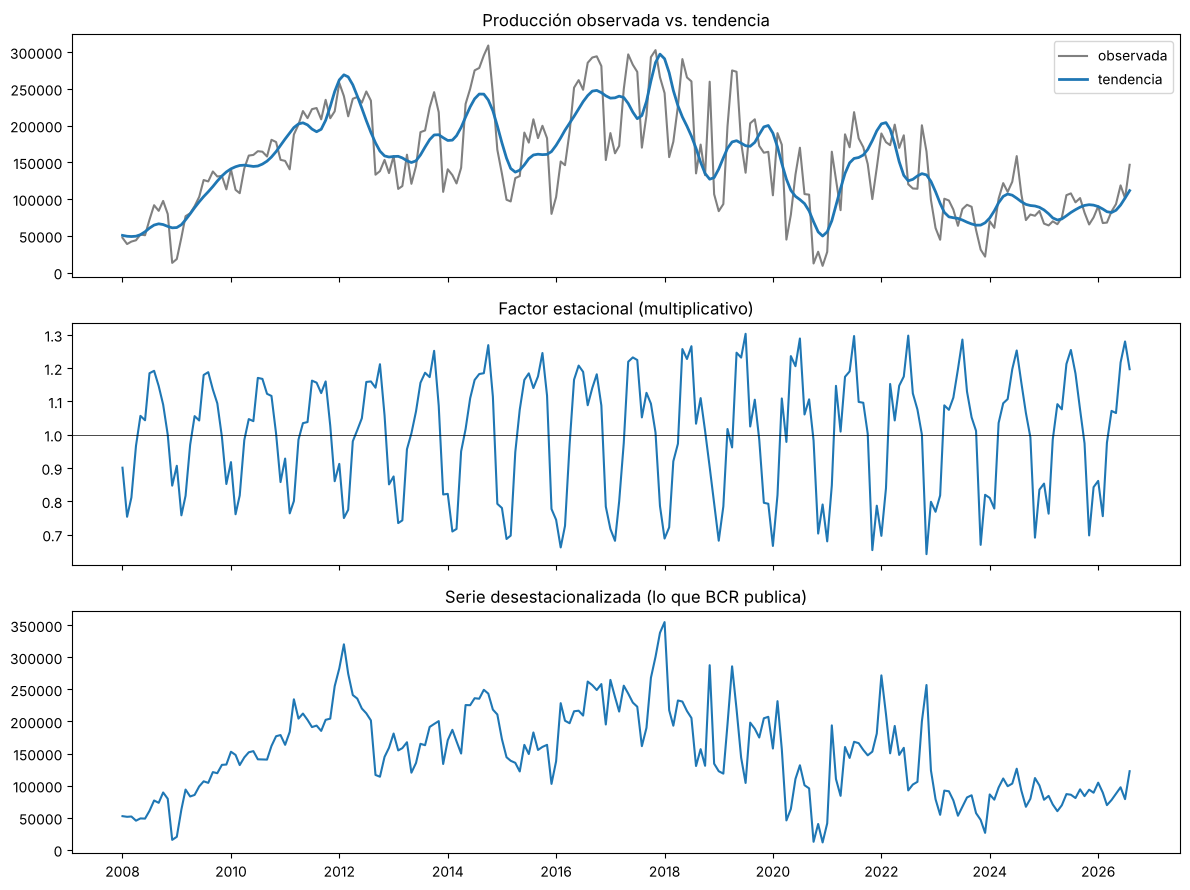

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(serie.index, serie.values, label="observada", color="gray")
axes[0].plot(comp.index, comp["tendencia"], label="tendencia", lw=2)
axes[0].set_title("Producción observada vs. tendencia"); axes[0].legend()
axes[1].plot(comp.index, comp["estacional"]); axes[1].axhline(1, color="k", lw=0.5)
axes[1].set_title("Factor estacional (multiplicativo)")
axes[2].plot(comp.index, comp["desestacionalizada"])
axes[2].set_title("Serie desestacionalizada (lo que BCR publica)")
plt.tight_layout(); plt.show()

## 2. Réplica walk-forward: ¿qué tan bien estima?

Corrimos X-13 mes a mes (cada mes se reentrena con los datos anteriores y
predice el siguiente) sobre las cuatro series, usando el **mismo protocolo de
evaluación** (`scripts/evaluacion.py`) que los baselines. Ventana de test:
septiembre 2025 → agosto 2026 (12 meses).

Comparamos varias versiones del X-13:

| Modelo | Qué es |
|---|---|
| `x13_bcr` | `.spc` de BCR + criterio de selección log/nivel (desvío sobre toda la serie) |
| `x13_bcr_sel12m` | idem, con el desvío calculado sobre los últimos 12 meses |
| `x13_bcr_log` / `x13_bcr_nivel` | `.spc` de BCR, siempre en log / siempre en nivel |
| `x13_auto` | réplica automática anterior (spec mínimo), como referencia |

Los `.spc` no tienen outliers fijos ni identificación automática de outliers,
así que el walk-forward no tiene leakage por ese lado.

> Con la config BCR cada corrida tarda 10-40 s; el walk-forward completo
> (144 corridas) tarda ~15 min en paralelo, por eso se deja precalculado en
> `results/`.


In [5]:
from pathlib import Path

# Usamos la tabla de integración (baselines de Andrés + X-13, armada por
# scripts/comparacion.py). Si todavía no está, caemos al x13.csv solo.
comp_path = Path("../results/comparacion.csv")
if comp_path.exists():
    comp_df = pd.read_csv(comp_path)
else:
    comp_df = pd.read_csv("../results/x13.csv")
    print("(falta results/comparacion.csv: corré scripts/comparacion.py; muestro solo X-13)\n")
tabla_mape = comp_df.pivot_table(index="serie", columns="modelo", values="MAPE_pct").round(1)
tabla_signo = comp_df.pivot_table(index="serie", columns="modelo", values="acierto_signo_pct").round(0)
orden = [m for m in ["naive", "naive_estacional", "x13_auto", "x13_bcr_log", "x13_bcr_nivel",
                     "x13_bcr", "x13_bcr_sel12m"] if m in tabla_mape.columns]
tabla_mape, tabla_signo = tabla_mape[orden], tabla_signo[orden]
print("MAPE por serie y modelo (menor = mejor):")
print(tabla_mape.to_string())
print("\nAcierto de signo (mayor = mejor):")
print(tabla_signo.to_string())

MAPE por serie y modelo (menor = mejor):
modelo           naive  naive_estacional  x13_auto  x13_bcr_log  x13_bcr_nivel  x13_bcr  x13_bcr_sel12m
serie                                                                                                  
biodiesel         18.2              15.8      21.0         21.0           19.7     19.7            21.0
bioetanol_cana    28.4              15.5      16.4         15.4           16.4     16.4            15.0
bioetanol_maiz     6.6               6.6       6.0          6.1            6.0      6.0             5.9
bioetanol_total   10.3               5.0       7.5          9.7            7.5      7.5             7.5

Acierto de signo (mayor = mejor):
modelo           naive  naive_estacional  x13_auto  x13_bcr_log  x13_bcr_nivel  x13_bcr  x13_bcr_sel12m
serie                                                                                                  
biodiesel          0.0              58.0      67.0         67.0           67.0     67.0     

### Criterio de selección log / nivel

BCR corre cada serie en log y en nivel y se queda con la de menor desvío
estándar de la variación logarítmica mensual de la tendencia-ciclo (D12). No
sabemos sobre qué ventana calcula ese desvío, así que probamos dos: toda la
serie y los últimos 12 meses. Qué eligió cada una, mes a mes:


In [6]:
sel = pd.read_csv("../results/seleccion_x13_bcr.csv")
print(sel.groupby("serie")[["elegido", "elegido_12m"]].value_counts().to_string())
sel[sel.datos_hasta == "2026-07"][["serie", "criterio_log", "criterio_nivel",
                                   "criterio_12m_log", "criterio_12m_nivel",
                                   "elegido", "elegido_12m"]].round(4)


serie            elegido  elegido_12m
biodiesel        nivel    log            12
bioetanol_cana   nivel    nivel          10
                          log             2
bioetanol_maiz   nivel    nivel           9
                          log             3
bioetanol_total  nivel    nivel          12


,serie,criterio_log,criterio_nivel,criterio_12m_log,criterio_12m_nivel,elegido,elegido_12m
11,biodiesel,0.0699,0.0653,0.0251,0.0316,nivel,log
23,bioetanol_cana,0.0405,0.0349,0.0121,0.0126,nivel,log
35,bioetanol_maiz,0.0376,0.0346,0.0142,0.0132,nivel,nivel
47,bioetanol_total,0.0527,0.0284,0.0114,0.0105,nivel,nivel


## 3. Criterio del DoD: los pronósticos con datos a julio 2026

BCR publica, con datos hasta julio 2026, 12 pronósticos (agosto 2026 → julio
2027): biodiesel en log y bioetanol en nivel. Corremos los mismos `.spc` con
los mismos datos. Los 12 de cada variante están en
`results/pronostico_x13_bcr_2026-07.csv` y el de agosto contra BCR, en
`results/pronostico_agosto2026.csv`:


In [7]:
pa = pd.read_csv("../results/pronostico_agosto2026.csv")
print(pa.to_string(index=False))

doce = pd.read_csv("../results/pronostico_x13_bcr_2026-07.csv")
doce.pivot_table(index="fecha", columns=["serie", "variante"], values="pronostico").round(0)


          serie variante  mi_pronostico  bcr_winx13  real_publicado  dif_vs_bcr_pct
      biodiesel      log         103923      103922          146604             0.0
bioetanol_total    nivel         140394      140394          139521            -0.0


serie      biodiesel           bioetanol_total          
variante         log     nivel             log     nivel
fecha                                                   
2026-08-01  103923.0  108390.0        140153.0  140394.0
2026-09-01  114343.0  117120.0        132378.0  129391.0
2026-10-01  114107.0  118528.0        130823.0  127647.0
2026-11-01  122660.0  119355.0        131650.0  122815.0
2026-12-01  120378.0  124638.0        124337.0  115089.0
2027-01-01  127666.0  130331.0        123464.0  110443.0
2027-02-01  124125.0  127300.0        125045.0  103098.0
2027-03-01  130603.0  128826.0        125624.0  105371.0
2027-04-01  126331.0  133139.0        115795.0   95827.0
2027-05-01  132297.0  136063.0        126339.0  108323.0
2027-06-01  127621.0  142121.0        130893.0  123310.0
2027-07-01  133261.0  138833.0        139969.0  137738.0

Con los `.spc` de BCR, **los 12 pronósticos coinciden con el Excel de BCR**
(`data/modelo_bcr_biocombustibles.xlsx`) en biodiesel (log) y bioetanol
(nivel), con diferencias menores a 0,00001 %. Agosto, por ejemplo: 103.922,6 tn
contra 103.922 en biodiesel y 140.393,7 m³ contra 140.394 en bioetanol.

Con datos a julio 2026, el criterio sobre la serie completa elige **nivel** en
biodiesel (BCR usa log). Calculado sobre los últimos 12 meses, elige log en
biodiesel y nivel en bioetanol, igual que BCR.

## 4. Conclusiones

1. **La réplica automática ya daba lo mismo que la config BCR en la misma
   transformación.** `x13_auto` coincide exactamente con `x13_bcr_log` en
   biodiesel y con `x13_bcr_nivel` en bioetanol. Lo que agrega el `.spc`
   (`seasonalma`, `maxiter`, diagnósticos) no cambia el pronóstico. Lo que
   importa es **la elección log/nivel**.
2. **El X-13 de BCR sigue perdiendo contra el naive estacional** en biodiesel
   (21,0% con log, como BCR; 19,7% si el criterio elige nivel, contra 15,8%) y
   en bioetanol total (7,5% contra 5,0%). En maíz y caña queda apenas
   adelante (5,9% y 15,0% con el criterio de 12 meses).
3. **Afinar el X-13 da poco**: la mejor elección de transformación mueve el
   MAPE 1-2 puntos. El margen grande está en cambiar de modelo.

**Benchmark a superar por serie** (el mejor entre las versiones del X-13 y
los baselines, test sep-2025 → ago-2026):

| Serie | Mejor actual | MAPE |
|---|---|---|
| Biodiesel | naive estacional | ~15,8% |
| Bioetanol total | naive estacional | ~5,0% |
| Bioetanol maíz | X-13 BCR (criterio 12 m) | ~5,9% |
| Bioetanol caña | X-13 BCR (criterio 12 m) | ~15,0% |

Nuestros modelos (SARIMAX, ML, LSTM) tienen que mejorar **el mejor de cada
fila**.

> **Ojo con "el modelo de BCR".** No es un modelo fijo: BCR también usa
> selección automática (el ARIMA lo elige `automdl` en cada corrida, y la
> transformación sale de su criterio log/nivel). Por eso comparamos contra
> su procedimiento completo (`x13_bcr` / `x13_bcr_sel12m`) y dejamos
> `x13_auto` como referencia para separar cuánto se gana ajustando el X-13
> de cuánto se gana cambiando de modelo.
